# EE3703 workbench tool detection: model training

Classes: `0 drill`, `1 scissor`, `2 screwdriver`. Images are 640 x 640.

**To run on Colab**
1. Choose Runtime > Change runtime type > GPU.
2. Run all cells. Section 1 asks you to upload `dataset.zip`, or set `USE_DRIVE = True` if it is in your Google Drive.

Colab clears its files when the runtime ends, so save your checkpoints to Drive.

**Rules**
- Use validation for every decision: epochs, thresholds, anchors, hyperparameters and model choice. Compute YOLOv2 anchors from `train` only.
- Don't touch the test split until every setting is fixed, then evaluate on it once.

## About the data

The task is to detect three workbench tools. Final accuracy is measured on the 50 original test photos, so originals are the images that matter most.

| Split | Used for | Images | Originals | Public | Drill boxes | Scissor boxes | Screwdriver boxes |
|---|---|---:|---:|---:|---:|---:|---:|
| train | Training | 358 | 66 | 292 | 174 | 178 | 181 |
| valid | All decisions | 92 | 17 | 75 | 52 | 47 | 47 |
| test | Final evaluation, once | 50 | 50 | 0 | 26 | 36 | 28 |

**Where the images come from**
- **Originals (133):** our own phone photos of workbench scenes. Some were compressed by a messaging app before use, to 1280 pixels on the long side.
- **Public (367):** Open Images V7 (160), Working Tool Detection v2 (95), Hardware Tools Complete v2 (66), METU-ALET (29), PRACTICAS Drill v1 (11) and Tool Monitoring System v3 (6).

**What to expect**
- **Balance:** the classes are balanced by box count, not image count. Screwdrivers appear in fewer images because some scenes hold several.
- **Scene density:** train originals average 2.5 boxes per image, and train public images average 1.3.
- **Object size:** median training box sizes are about 303 x 297 pixels for drills, 216 x 217 for scissors and 108 x 94 for screwdrivers. Screwdrivers are small and thin, and were the hardest class in early tests.
- **Small original validation set:** the original valid images hold only 42 boxes, so small differences there can be noise.

**How boxes were labelled**
- Every visible drill, scissor and screwdriver has a box, including partly hidden tools that can still be identified.
- Drill boxes include the battery and any fitted bit.
- Other tools, such as hammers, pliers, saws and knives, have no box and count as background.

**Files in `dataset/`**
- `train/`, `valid/` and `test/`: each holds `images/`, YOLO labels in `labels/` (`class cx cy w h`, normalized) and COCO labels in `annotations.coco.json` (`category_id` is the class plus 1). You don't need to read these directly if you use the loaders below.
- `manifest.csv`: split, origin, source, capture group and box counts for every image.
- `classes.txt` and `data.yaml`: the class mapping.

## Preprocessing

**Already applied to the image files (don't repeat these)**

| Step | What was done |
|---|---|
| Cleaning | Removed unreadable images, wrong or missing labels, unsuitable scenes and near-duplicates |
| Class mapping | Source class names mapped to the three classes, and boxes for other classes dropped |
| Orientation | Originals made upright, and public photos with unreliable rotation data excluded |
| Letterbox | Long side resized to 640 with bilinear scaling, centred, and padded to 640 x 640 with gray 114 |
| Boxes | Scaled and shifted with the image, then clipped to image bounds |
| Splitting | Photos of the same scene or video stay in one split, so related images can't leak between splits; a similarity check found no near-duplicates across splits |

The gray bars in the images are this padding, not an error.

**Applied each time an image loads (by the code in section 2)**

| Step | train | valid | test |
|---|:---:|:---:|:---:|
| ImageNet normalization (mean 0.485, 0.456, 0.406; std 0.229, 0.224, 0.225) | Yes | Yes | Yes |
| Augmentation | Yes | No | No |
| Class-aware sampling | Yes | No | No |

The normalization matches a standard ImageNet-pretrained ResNet-18, so don't add your own.

In [1]:
from pathlib import Path

import torch

print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none, check the runtime type")
# Use `device` when you move models and data in section 5.
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(3703)

torch 2.11.0+cu130 | GPU: Tesla T4


## 1. Get the dataset

In [2]:
import zipfile

USE_DRIVE = False
DRIVE_ZIP = "/content/drive/MyDrive/dataset.zip"  # only used when USE_DRIVE is True

if not Path("dataset/manifest.csv").exists():
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        archive = DRIVE_ZIP
    else:
        archive = "dataset.zip"
        if not Path(archive).exists():
            from google.colab import files
            files.upload()  # choose dataset.zip
    with zipfile.ZipFile(archive) as z:
        z.extractall(".")

DATASET = Path("dataset")
for split, expected in {"train": 358, "valid": 92, "test": 50}.items():
    images = len(list((DATASET / split / "images").glob("*.jpg")))
    labels = len(list((DATASET / split / "labels").glob("*.txt")))
    assert images == labels == expected, f"{split}: {images} images, {labels} labels, expected {expected}"
print("dataset ok: 358 train, 92 valid, 50 test")

Saving dataset.zip to dataset.zip
dataset ok: 358 train, 92 valid, 50 test


## 2. Data code

### Augmentation (training only)

Each draw of an image gets a new random version, in this order:

| Step | Setting |
|---|---|
| Horizontal flip | Probability 0.5 |
| Rotation | Up to ±15° |
| Shift | Up to ±8% of the image |
| Scale | 0.8 to 1.2, or 0.7 to 1.3 if the image holds a scissor |
| Brightness and contrast | Up to ±20% |
| Gamma | 0.8 to 1.25 |
| Hue and saturation | Hue up to ±8°, saturation 0.8 to 1.2 |
| Gaussian blur | Probability 0.15 |
| Sensor noise | Probability 0.15, sigma 6 |
| Scissor occlusion | Probability 0.5, a gray patch over 10% to 30% of one scissor box |
| Cutout | Probability 0.3, a gray square with sides up to 128 pixels |
| Mosaic | Off (`MOSAIC_P = 0.0`), because it showed no gain in early tests |

- **Box safety:** a rotation, shift or patch that would hide more than 70% of an object is discarded, so no box is lost.
- **Rotated boxes:** the new box is the upright rectangle around the rotated one, so it can be slightly looser than the original.
- **Empty areas:** space left by rotation or shifting is filled with gray 114.

In [3]:
import random

import cv2
import numpy as np

SIZE = 640
SCISSOR = 1
MIN_VISIBLE = 0.3  # a box must stay at least 30% visible, so at most 70% is hidden
MIN_SIDE = 4.0
GEOMETRIC_TRIES = 5
MOSAIC_TRIES = 10
CONFIG = {
    "horizontal_flip_p": 0.5,
    "rotate_deg": 15.0,
    "translate_fraction": 0.08,
    "scale_range": [0.8, 1.2],
    "brightness_contrast": 0.2,
    "gamma_range": [0.8, 1.25],
    "hue_shift_deg": 8,
    "saturation_range": [0.8, 1.2],
    "blur_p": 0.15,
    "noise_p": 0.15,
    "noise_sigma": 6.0,
    "cutout_p": 0.3,
    "cutout_fraction": 0.2,
    "scissor_scale_range": [0.7, 1.3],
    "scissor_occlusion_p": 0.5,
    "scissor_occlusion_area": [0.1, 0.3],
    "mosaic_p": 0.0,
    "minimum_visible_box_fraction": MIN_VISIBLE,
}


def _visible(boxes: np.ndarray, reference_area: np.ndarray, bounds: tuple[float, float, float, float] = (0, 0, SIZE, SIZE)) -> tuple[np.ndarray, np.ndarray]:
    """Return boxes clipped to bounds and a mask of those that stay usable."""
    clipped = boxes.copy()
    clipped[:, [0, 2]] = clipped[:, [0, 2]].clip(bounds[0], bounds[2])
    clipped[:, [1, 3]] = clipped[:, [1, 3]].clip(bounds[1], bounds[3])
    width, height = clipped[:, 2] - clipped[:, 0], clipped[:, 3] - clipped[:, 1]
    return clipped, (width >= MIN_SIDE) & (height >= MIN_SIDE) & (width * height >= MIN_VISIBLE * reference_area)


def _warp_boxes(boxes: np.ndarray, matrix: np.ndarray) -> np.ndarray:
    corners = np.ones((len(boxes), 4, 3))
    corners[:, 0, :2] = boxes[:, [0, 1]]
    corners[:, 1, :2] = boxes[:, [2, 1]]
    corners[:, 2, :2] = boxes[:, [2, 3]]
    corners[:, 3, :2] = boxes[:, [0, 3]]
    moved = corners @ matrix.T
    return np.concatenate([moved.min(axis=1), moved.max(axis=1)], axis=1)


# Flip, then try up to 5 random rotation, scale and shift combinations that keep every box usable.
# If none works, only the flip is kept.
def geometric(image: np.ndarray, boxes: np.ndarray, labels: np.ndarray, rng: random.Random) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    if rng.random() < CONFIG["horizontal_flip_p"]:
        image = image[:, ::-1].copy()
        if len(boxes):
            boxes = boxes.copy()
            boxes[:, [0, 2]] = SIZE - boxes[:, [2, 0]]
    scale_range = CONFIG["scissor_scale_range"] if (labels == SCISSOR).any() else CONFIG["scale_range"]
    shift = CONFIG["translate_fraction"] * SIZE
    for _ in range(GEOMETRIC_TRIES):
        matrix = cv2.getRotationMatrix2D((SIZE / 2, SIZE / 2), rng.uniform(-CONFIG["rotate_deg"], CONFIG["rotate_deg"]), rng.uniform(*scale_range))
        matrix[:, 2] += (rng.uniform(-shift, shift), rng.uniform(-shift, shift))
        if not len(boxes):
            return cv2.warpAffine(image, matrix, (SIZE, SIZE), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114)), boxes, labels
        moved = _warp_boxes(boxes, matrix)
        clipped, usable = _visible(moved, (moved[:, 2] - moved[:, 0]) * (moved[:, 3] - moved[:, 1]))
        if usable.all():
            return cv2.warpAffine(image, matrix, (SIZE, SIZE), flags=cv2.INTER_LINEAR, borderValue=(114, 114, 114)), clipped.astype(np.float32), labels
    return image, boxes, labels


# Colour changes and noise only, so boxes don't move.
def photometric(image: np.ndarray, rng: random.Random) -> np.ndarray:
    limit = CONFIG["brightness_contrast"]
    output = image.astype(np.float32) * rng.uniform(1 - limit, 1 + limit) + 255 * rng.uniform(-limit, limit) / 2
    output = 255 * (output.clip(0, 255) / 255) ** rng.uniform(*CONFIG["gamma_range"])
    hsv = cv2.cvtColor(output.astype(np.uint8), cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + rng.uniform(-CONFIG["hue_shift_deg"], CONFIG["hue_shift_deg"]) / 2) % 180
    hsv[..., 1] = (hsv[..., 1] * rng.uniform(*CONFIG["saturation_range"])).clip(0, 255)
    output = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if rng.random() < CONFIG["blur_p"]:
        output = cv2.GaussianBlur(output, (5, 5), 0)
    if rng.random() < CONFIG["noise_p"]:
        noise = np.random.default_rng(rng.randrange(2**32)).normal(0, CONFIG["noise_sigma"], output.shape)
        output = (output + noise).clip(0, 255).astype(np.uint8)
    return output


def _try_patch(image: np.ndarray, hidden: np.ndarray, boxes: np.ndarray, x: int, y: int, w: int, h: int) -> bool:
    """Grey out a rectangle unless the total hidden area of any box would pass the limit."""
    trial = hidden.copy()
    trial[y:y + h, x:x + w] = True
    for x1, y1, x2, y2 in boxes.astype(int):
        area = trial[y1:y2, x1:x2]
        if area.size and area.mean() > 1 - MIN_VISIBLE:
            return False
    hidden[y:y + h, x:x + w] = True
    image[y:y + h, x:x + w] = 114
    return True


def scissor_occlusion(image: np.ndarray, hidden: np.ndarray, boxes: np.ndarray, labels: np.ndarray, rng: random.Random) -> None:
    """Partly cover one scissor box, since thin blades and handles are often occluded."""
    scissors = boxes[labels == SCISSOR]
    if not len(scissors) or rng.random() >= CONFIG["scissor_occlusion_p"]:
        return
    x1, y1, x2, y2 = scissors[rng.randrange(len(scissors))]
    share = rng.uniform(*CONFIG["scissor_occlusion_area"])
    w, h = max(int((x2 - x1) * share ** 0.5), 1), max(int((y2 - y1) * share ** 0.5), 1)
    x = int(rng.uniform(x1, max(x2 - w, x1)))
    y = int(rng.uniform(y1, max(y2 - h, y1)))
    _try_patch(image, hidden, boxes, x, y, min(w, SIZE - x), min(h, SIZE - y))


# A gray square at a random place, skipped if it would hide too much of a box.
def cutout(image: np.ndarray, hidden: np.ndarray, boxes: np.ndarray, rng: random.Random) -> None:
    if rng.random() >= CONFIG["cutout_p"]:
        return
    side = int(SIZE * CONFIG["cutout_fraction"] * rng.uniform(0.5, 1))
    _try_patch(image, hidden, boxes, rng.randrange(SIZE - side), rng.randrange(SIZE - side), side, side)


# The full training augmentation for one image.
def augment(image: np.ndarray, boxes: np.ndarray, labels: np.ndarray, rng: random.Random) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    image, boxes, labels = geometric(image, boxes, labels, rng)
    image = photometric(image, rng).copy()
    hidden = np.zeros((SIZE, SIZE), dtype=bool)
    scissor_occlusion(image, hidden, boxes, labels, rng)
    cutout(image, hidden, boxes, rng)
    return image, boxes, labels


def mosaic(samples: list[tuple[np.ndarray, np.ndarray, np.ndarray]], rng: random.Random) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Join four training images; call with samples from the training split only."""
    cx, cy = rng.randint(SIZE // 4, 3 * SIZE // 4), rng.randint(SIZE // 4, 3 * SIZE // 4)
    canvas = np.full((SIZE, SIZE, 3), 114, dtype=np.uint8)
    regions = [(0, 0, cx, cy), (cx, 0, SIZE, cy), (0, cy, cx, SIZE), (cx, cy, SIZE, SIZE)]
    all_boxes, all_labels = [np.zeros((0, 4), np.float32)], [np.zeros(0, np.int64)]
    for (x1, y1, x2, y2), (image, boxes, labels) in zip(regions, samples):
        width, height = x2 - x1, y2 - y1
        best = None
        # Choose the crop that leaves the fewest cut-off remnants without a label.
        for _ in range(MOSAIC_TRIES):
            offset_x, offset_y = rng.randint(0, SIZE - width), rng.randint(0, SIZE - height)
            moved = boxes.copy()
            moved[:, [0, 2]] += x1 - offset_x
            moved[:, [1, 3]] += y1 - offset_y
            clipped, usable = _visible(moved, (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), (x1, y1, x2, y2))
            touching = (moved[:, 2] > x1) & (moved[:, 0] < x2) & (moved[:, 3] > y1) & (moved[:, 1] < y2)
            remnants = int((touching & ~usable).sum())
            score = (remnants, -int(usable.sum()))
            if best is None or score < best[0]:
                best = (score, offset_x, offset_y, clipped[usable], labels[usable])
        _, offset_x, offset_y, kept, kept_labels = best
        canvas[y1:y2, x1:x2] = image[offset_y:offset_y + height, offset_x:offset_x + width]
        all_boxes.append(kept.astype(np.float32))
        all_labels.append(kept_labels)
    return canvas, np.concatenate(all_boxes), np.concatenate(all_labels)


### Data loading

`ToolDataset` returns a normalized image tensor and a target dictionary:

| Key | Contents |
|---|---|
| `boxes` | Float tensor `[N, 4]`, in pixels: `[x1, y1, x2, y2]` on the 640 x 640 image |
| `labels` | Integer tensor `[N]`: 0 drill, 1 scissor, 2 screwdriver |
| `file_name` | Image file name |
| `origin` | `original` or `public` |

**Sampling:** each epoch draws 358 images with replacement, so some repeat with a different augmentation and others are skipped. Images holding rarer classes are weighted up, with the class weight capped at 2 times. The training boxes are already nearly balanced, so the effect is small.

**Splits:** `train` and `valid` are for development. `trainval` combines them for the final retrain. `test` is refused unless you pass `allow_test=True`.

In [4]:
import csv
import random
from pathlib import Path

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, WeightedRandomSampler

# OpenCV threads can hang inside DataLoader worker processes.
cv2.setNumThreads(0)

SIZE = 640
NUM_CLASSES = 3
TRAINING_SPLITS = ("train", "trainval")
# ImageNet statistics, because both detectors use a standard ResNet-18 backbone.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
MAX_CLASS_WEIGHT = 2.0
# Starting values; recheck them on your detector, using validation only.
ORIGINAL_WEIGHT = 1.0
MOSAIC_P = 0.0


def normalize(image: np.ndarray) -> torch.Tensor:
    """Convert an RGB uint8 HWC array to the tensor both models take."""
    tensor = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    return (tensor - torch.tensor(MEAN).view(3, 1, 1)) / torch.tensor(STD).view(3, 1, 1)


def denormalize(tensor: torch.Tensor) -> np.ndarray:
    """Undo normalize for visual checks."""
    image = tensor * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return (image.permute(1, 2, 0).clamp(0, 1) * 255).round().byte().numpy()


def boxes_to_yolo(boxes: torch.Tensor) -> torch.Tensor:
    """Convert pixel xyxy boxes to normalized cx, cy, w, h."""
    return torch.stack([(boxes[:, 0] + boxes[:, 2]) / 2, (boxes[:, 1] + boxes[:, 3]) / 2, boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]], dim=1) / SIZE


class ToolDataset(Dataset):
    """Images and targets for one split; see the table above for the target format."""

    def __init__(self, root: str | Path, split: str, augment: bool = False, mosaic_p: float = 0.0, origin: str | None = None, allow_test: bool = False) -> None:
        if split == "test" and not allow_test:
            raise ValueError("The test split is locked; pass allow_test=True only for the final evaluation.")
        if split not in TRAINING_SPLITS and (augment or mosaic_p):
            raise ValueError("Augmentation is for training data only.")
        self.root, self.split, self.augment, self.mosaic_p = Path(root), split, augment, mosaic_p
        # "trainval" is only for the final retrain, after validation has fixed every setting.
        folders = ("train", "valid") if split == "trainval" else (split,)
        with (self.root / "manifest.csv").open() as handle:
            rows = [r for r in csv.DictReader(handle) if r["split"] in folders and (origin is None or r["origin"] == origin)]
        self.names = [r["file_name"] for r in rows]
        self.origins = [r["origin"] for r in rows]
        self.folders = [r["split"] for r in rows]
        self.boxes, self.labels = [], []
        for name, folder in zip(self.names, self.folders):
            lines = [l.split() for l in (self.root / folder / "labels" / f"{Path(name).stem}.txt").read_text().split("\n") if l]
            values = np.array([[float(v) * SIZE for v in l[1:]] for l in lines], np.float32).reshape(-1, 4)
            # Clip because labels are stored to 6 decimals, which can land a tiny fraction outside the image.
            self.boxes.append(np.stack([values[:, 0] - values[:, 2] / 2, values[:, 1] - values[:, 3] / 2, values[:, 0] + values[:, 2] / 2, values[:, 1] + values[:, 3] / 2], axis=1).clip(0, SIZE))
            self.labels.append(np.array([int(l[0]) for l in lines], np.int64))
        self.sample_weights: list[float] | None = None

    def __len__(self) -> int:
        return len(self.names)

    def _raw(self, index: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        image = cv2.cvtColor(cv2.imread(str(self.root / self.folders[index] / "images" / self.names[index])), cv2.COLOR_BGR2RGB)
        return image, self.boxes[index].copy(), self.labels[index].copy()

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict]:
        image, boxes, labels = self._raw(index)
        if self.augment:
            # Seeded from torch so each worker and epoch draws a different, reproducible augmentation.
            rng = random.Random(int(torch.randint(0, 2**31 - 1, (1,)).item()))
            if rng.random() < self.mosaic_p:
                others = rng.choices(range(len(self)), weights=self.sample_weights, k=3)
                image, boxes, labels = mosaic([augment(*self._raw(i), rng) for i in [index, *others]], rng)
            else:
                image, boxes, labels = augment(image, boxes, labels, rng)
        return normalize(image), {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "file_name": self.names[index],
            "origin": self.origins[index],
        }


# Images stack into one tensor. Targets stay a list because box counts differ between images.
def collate(batch: list[tuple[torch.Tensor, dict]]) -> tuple[torch.Tensor, list[dict]]:
    return torch.stack([item[0] for item in batch]), [item[1] for item in batch]


def image_weights(dataset: ToolDataset, original_weight: float = ORIGINAL_WEIGHT) -> list[float]:
    """Per-image weights from training boxes only.

    Originals are upweighted first. Class weights are then the inverse of the resulting
    box frequency, capped at 2 times, so favouring originals does not unbalance the classes.
    """
    if dataset.split not in TRAINING_SPLITS:
        raise ValueError("Sampling weights are computed from training data only.")
    base = [original_weight if origin == "original" else 1.0 for origin in dataset.origins]
    counts = np.zeros(NUM_CLASSES)
    for weight, labels in zip(base, dataset.labels):
        counts += weight * np.bincount(labels, minlength=NUM_CLASSES)
    class_weight = np.minimum(counts.max() / counts, MAX_CLASS_WEIGHT)
    return [weight * (float(class_weight[labels].max()) if len(labels) else 1.0) for weight, labels in zip(base, dataset.labels)]


def expected_box_counts(dataset: ToolDataset, weights: list[float]) -> np.ndarray:
    """Boxes per class one epoch is expected to contain under the given weights."""
    scale = len(weights) / sum(weights)
    counts = np.zeros(NUM_CLASSES)
    for weight, labels in zip(weights, dataset.labels):
        counts += scale * weight * np.bincount(labels, minlength=NUM_CLASSES)
    return counts


def make_train_sampler(dataset: ToolDataset, original_weight: float = ORIGINAL_WEIGHT, generator: torch.Generator | None = None) -> WeightedRandomSampler:
    weights = image_weights(dataset, original_weight)
    dataset.sample_weights = weights
    return WeightedRandomSampler(weights, num_samples=len(dataset), replacement=True, generator=generator)


## 3. Data loaders

This builds the loaders and prints the shape of one batch. Each image can hold a different number of boxes, so `targets` is a list with one dictionary per image.

**Two settings to recheck on your detector, using validation:**

| Setting | Meaning | Start | When to change |
|---|---|---:|---|
| `MOSAIC_P` | Probability that a training image is replaced by a mosaic, which stitches 4 training images into one. `0.2` means about 1 in 5. | `0.0` (off) | Try `0.2` if your detector struggles with small or cut-off tools |
| `ORIGINAL_WEIGHT` | How much more likely each original photo is to be drawn than a public image. An epoch stays at 358 draws, so originals repeat more often and some public images are skipped. | `1.0` (originals are about 19% of draws) | Try `2.0` (about 31%) if results on original valid images are substantially below those on public valid images |

The final test uses only originals, so a higher `ORIGINAL_WEIGHT` focuses training on them, but too high a value can overfit to their few scenes. In early tests, neither `MOSAIC_P = 0.2` nor `ORIGINAL_WEIGHT = 2.0` gave a measurable gain.

In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_set = ToolDataset(DATASET, "train", augment=True, mosaic_p=MOSAIC_P)
sampler = make_train_sampler(train_set, original_weight=ORIGINAL_WEIGHT)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, sampler=sampler, collate_fn=collate, num_workers=2)

valid_set = ToolDataset(DATASET, "valid")
valid_loader = DataLoader(valid_set, batch_size=BATCH_SIZE, collate_fn=collate, num_workers=2)

images, targets = next(iter(train_loader))
print("images", images.shape)  # normalized [B, 3, 640, 640]
print("boxes", targets[0]["boxes"].shape, "labels", targets[0]["labels"].tolist())  # pixel [x1, y1, x2, y2]
print("for YOLOv2", boxes_to_yolo(targets[0]["boxes"]).shape)  # normalized cx, cy, w, h

images torch.Size([8, 3, 640, 640])
boxes torch.Size([1, 4]) labels [0]
for YOLOv2 torch.Size([1, 4])


## 4. Check the boxes (for review purpose)

Each box should sit on the right tool. Green is drill, yellow is scissor and cyan is screwdriver.

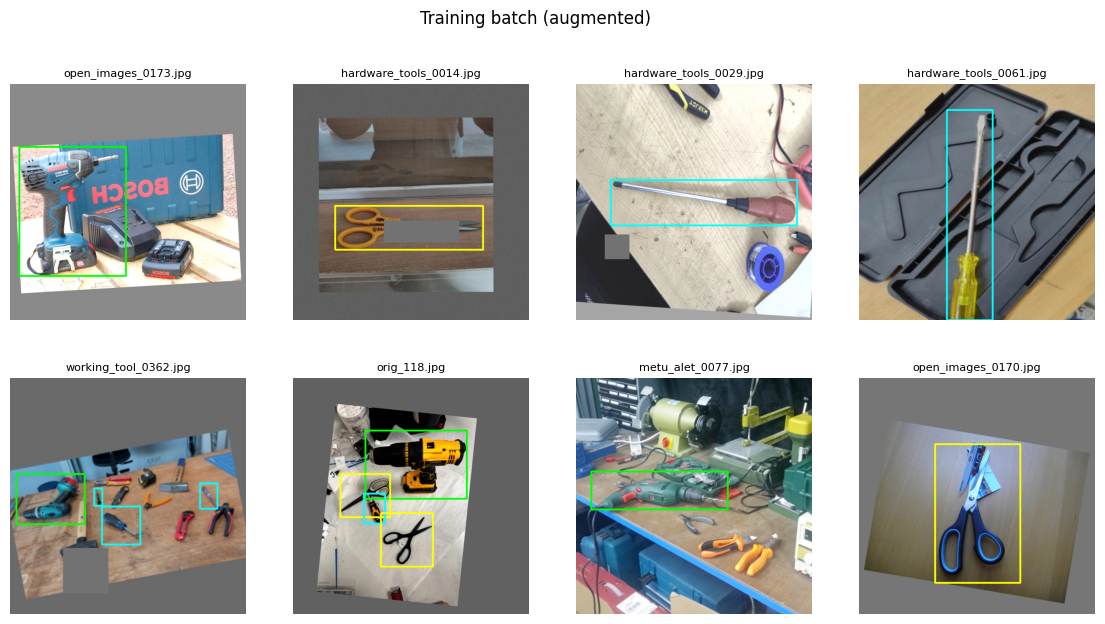

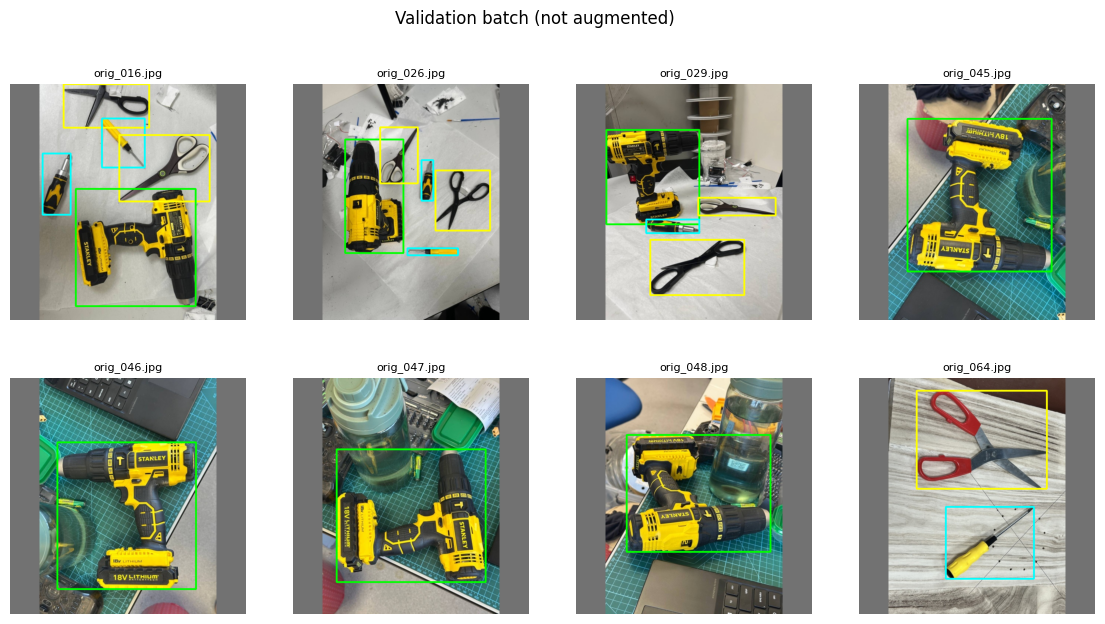

In [6]:
import cv2
import matplotlib.pyplot as plt

COLOURS = [(0, 255, 0), (255, 255, 0), (0, 255, 255)]


def show_batch(images, targets, title, count=8):
    figure, axes = plt.subplots(2, 4, figsize=(14, 7))
    figure.suptitle(title)
    for axis, image, target in zip(axes.flat, images[:count], targets[:count]):
        picture = denormalize(image).copy()
        for box, label in zip(target["boxes"].int().tolist(), target["labels"].tolist()):
            cv2.rectangle(picture, tuple(box[:2]), tuple(box[2:]), COLOURS[label], 3)
        axis.imshow(picture)
        axis.set_title(target["file_name"], fontsize=8)
        axis.axis("off")
    plt.show()


show_batch(images, targets, "Training batch (augmented)")
show_batch(*next(iter(valid_loader)), "Validation batch (not augmented)")

## 5. Model training

Add the Faster R-CNN and YOLOv2 code here, using `train_loader` and `valid_loader`. Move data to the GPU with `images.to(device)` and `target["boxes"].to(device)`.

**Connecting your model**
- **Moving targets to the GPU:** move only `boxes` and `labels`. `file_name` and `origin` are strings, so `{k: v.to(device) for k, v in target.items()}` will crash.
- **Faster R-CNN:** labels are 0, 1 and 2 with no background class. If your model reserves 0 for background, use `target["labels"] + 1` and `num_classes = 4`.
- **YOLOv2:** convert with `boxes_to_yolo(target["boxes"])`, which gives values from 0 to 1. Multiply by the grid size (20 x 20 at stride 32). Compute anchors from `train_set.boxes`, which holds pixel `[x1, y1, x2, y2]` boxes before augmentation.
- **Fixed input size:** the loader always gives 640 x 640, so multi-scale training would need your own resizing.

**After every setting is fixed:**

```python
# 1. Retrain on train + valid, with the epoch count already fixed on validation
final_set = ToolDataset(DATASET, "trainval", augment=True, mosaic_p=MOSAIC_P)
final_loader = DataLoader(final_set, batch_size=BATCH_SIZE, sampler=make_train_sampler(final_set, original_weight=ORIGINAL_WEIGHT), collate_fn=collate, num_workers=2)

# 2. Load the test split once, for the final evaluation
test_set = ToolDataset(DATASET, "test", allow_test=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, collate_fn=collate, num_workers=2)
```